- Plot clean URLs as the background, then overlay the adversarial URLs --> found out whether the 3-character edits move a URL from the phishing side toward the legit side.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tldextract
import json, torch, torch.nn as nn
from transformers import BertConfig, BertModel, BertTokenizerFast
import sys
sys.path.insert(0, "..")
from src.load_data import load_splits
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
import torch
from pathlib import Path
import re

SEED = 42
N_PER_SET = 2000          # points sampled per set (prevent overplotting)
N_ADV = 600               # adversarial points per set
MAX_GROUP_FRAC = 1.00     
N_ARROWS = 40            # orig -> adv arrows drawn per adversarial set
TOP_GROUPS = 5            # color for top 5 domain groups; the rest -> "other"
GROUP_BY = "registered_domain"   
GROUP_ROW_SHOW_ADV = False #2nd row of plots do not include adversarial points --> clearer to see domain groups
PROJECTION = "pca"       # or "umap"
OUT_DIR = "../embedding_plots"

ARCHS = ["CNN", "BiLSTM", "URLBERT"]
LABEL_NAMES = {0: "phishing", 1: "legitimate"}

import os; os.makedirs(OUT_DIR, exist_ok=True)
_tld = tldextract.TLDExtract(suffix_list_urls=())  

/home/ubuntu/miniconda/envs/dsa4266/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Load data
- adversarial - keep only rows that were edited, flipped and not flipped are marked differently in the plots

In [2]:
import sys; sys.path.append("../src")
def canon(url):
    url = re.sub(r"^[A-Za-z][A-Za-z0-9+.\-]*://", "", str(url).strip())
    return re.sub(r"/+$", "", re.sub(r"^www\d*\.", "", url, flags=re.IGNORECASE))

_b = lambda s: s.astype(str).eq("True") 

def read_orig(path):
    df = pd.read_csv(path, keep_default_na=False).rename(columns={"URL": "url"})
    df["url"] = df["url"].map(canon)
    return df[["url", "label"]]                   

ORIG = {"train_orig": read_orig("../data/train.csv"), "test_orig": read_orig("../data/test.csv")}

def read_adv(path, split_urls):
    df = pd.read_csv(path, keep_default_na=False).rename(columns={"orig_URL": "orig_url", "URL": "adv_url"})
    n0 = len(df); df["n_edits"] = df["n_edits"].astype(int)
    dup = _b(df["duplicate"]) if "duplicate" in df else (df.n_edits > 0) & (df.adv_url.isin(split_urls) | df.adv_url.duplicated())
    df = df[(df.n_edits > 0) & ~dup].copy()                      # edited, non-duplicate; flipped or not
    df["flipped"] = _b(df["flipped"])
    df = df.assign(url=df["adv_url"], label=0)
    print(f"{Path(path).name}: kept {len(df)}/{n0}  (flipped {int(df.flipped.sum())}, not flipped {int((~df.flipped).sum())})")
    return df[["url", "label", "orig_url", "flipped"]].reset_index(drop=True)

A = Path("../data/adversarial"); tr, te = set(ORIG["train_orig"].url), set(ORIG["test_orig"].url)
ADV = {
    "CNN": dict(train_adv=read_adv(A/"cnn_train_adversarial.csv", tr),
                test_adv1=read_adv(A/"cnn_test_adversarial.csv", te),
                test_adv2=read_adv(A/"cnn_m2_test_adversarial.csv", te)),
    "URLBERT": dict(train_adv=read_adv("../data/urlbert_adv_train.csv", tr),
                    test_adv1=read_adv("../data/urlbert_adv_test.csv", te), test_adv2=read_adv("../data/urlbert_model2_adv_test.csv", te)),
    "BiLSTM": dict(train_adv=read_adv("../data/bilstm_adv_train.csv", tr), test_adv1=read_adv("../data/bilstm_adv_test.csv", te), test_adv2=read_adv("../data/bilstm_m2_adv_test.csv", te)), 
}
DATA_BY_ARCH = {a: {**ORIG, **s} for a, s in ADV.items()}
def get_data(arch, name): return DATA_BY_ARCH[arch].get(name)

cnn_train_adversarial.csv: kept 12635/15983  (flipped 884, not flipped 11751)
cnn_test_adversarial.csv: kept 6467/7939  (flipped 333, not flipped 6134)
cnn_m2_test_adversarial.csv: kept 5881/7847  (flipped 54, not flipped 5827)
urlbert_adv_train.csv: kept 13123/15476  (flipped 1481, not flipped 11642)
urlbert_adv_test.csv: kept 6077/7729  (flipped 3047, not flipped 3030)
urlbert_model2_adv_test.csv: kept 6125/7951  (flipped 344, not flipped 5781)
bilstm_adv_train.csv: kept 13811/15899  (flipped 2526, not flipped 11285)
bilstm_adv_test.csv: kept 6445/7876  (flipped 739, not flipped 5706)
bilstm_m2_adv_test.csv: kept 5994/7876  (flipped 64, not flipped 5930)


# Encoder
-  maps a list of URL strings -> np.ndarray (N, D) of PENULTIMATE-layer features (the vector that feeds the final classification layer)
- Dimensions also differ across CNN, BiLSTM and URLBERT - normalised the shift by each model’s class-centroid gap. Compare the ratios across architectures, not raw distances.

## note: penultimate layer has a built-in bias  
- trained to separate the classes, so S1 will look cleanly separated. 
- The informative parts are where the adversarial points land and the structure within each class. 
- Features the model discarded won’t show up --> absence of domain clustering there doesn’t prove the model ignores domain.

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def torch_encoder(model, tokenize, device, bs=256):
    # Returns the INPUT to the final nn.Linear (the penultimate vector)
    head = [m for m in model.modules() if isinstance(m, torch.nn.Linear)][-1]
    store = {}
    head.register_forward_hook(lambda m, inp, out: store.__setitem__("x", inp[0].detach().float().cpu()))
    model = model.to(device).eval()

    @torch.no_grad()
    def enc(urls):
        out = []
        for i in range(0, len(urls), bs):
            batch = tokenize(urls[i:i + bs])
            if isinstance(batch, dict):
                model(**{k: v.to(device) for k, v in batch.items()})
            elif isinstance(batch, tuple):                       # (input_ids, lengths) for the BiLSTM
                x, lengths = batch
                try:
                    model(x.to(device), lengths)                 
                except RuntimeError:
                    model(x.to(device), lengths.to(device))  
            else:
                model(batch.to(device))
            out.append(store["x"].numpy())
        return np.vstack(out)
    enc.model, enc.head = model, head
    return enc

def build(ckpt, loader, tokenize):
    # ckpt: path to the saved weights; loader: function that builds the model and loads them
    # (load_cnn / load_urlbert); tokenize: char_tokenize / bert_tokenize.
    if not Path(ckpt).exists():
        print(f"skip: {ckpt} not found"); return None
    return torch_encoder(loader(ckpt), tokenize, DEVICE)

# ---------- CNN ----------
vocab = json.load(open("../data/vocab.json")); cfg = json.load(open("../data/config.json"))
char_to_idx = {c: i for i, c in enumerate(vocab["index_to_string"])}
PAD_IDX, UNK_IDX, CHAR_MAX_LEN, VOCAB_SIZE = vocab["pad_idx"], vocab["unk_idx"], cfg["max_len"], len(char_to_idx)

class CharacterCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=32):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.conv1 = nn.Conv1d(embedding_dim, 128, kernel_size=5); self.conv2 = nn.Conv1d(128, 128, kernel_size=5)
        self.relu = nn.ReLU(); self.pool = nn.AdaptiveMaxPool1d(1); self.fc = nn.Linear(128, 1)
    def forward(self, x):
        x = self.embedding(x).transpose(1, 2)
        x = self.relu(self.conv1(x)); x = self.relu(self.conv2(x))
        return self.fc(self.pool(x).squeeze(2))

def char_tokenize(urls):
    arr = np.full((len(urls), CHAR_MAX_LEN), PAD_IDX, dtype=np.int64)
    for r, u in enumerate(map(canon, urls)):
        row = [char_to_idx.get(c, UNK_IDX) for c in u[:CHAR_MAX_LEN]]; arr[r, :len(row)] = row
    return torch.from_numpy(arr)

def load_cnn(path):
    m = CharacterCNN(VOCAB_SIZE, 32); m.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True)); return m

# ---------- URLBERT ----------
URLBERT_DIR = "../models/urlbert"
tok = BertTokenizerFast(vocab_file=f"{URLBERT_DIR}/bert_tokenizer/vocab.txt", do_lower_case=True)
_lens = [len(x) for x in tok(load_splits()["train"].URL.tolist())["input_ids"]]
BERT_MAX_LEN = min(int(np.percentile(_lens, 99)), 128)  # same rule as training

class URLBERTClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__(); self.encoder = encoder; self.dropout = nn.Dropout(0.1); self.fc = nn.Linear(768, 2)
    def forward(self, input_ids, attention_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.fc(self.dropout(h))

def load_urlbert(path):
    c = BertConfig.from_json_file(f"{URLBERT_DIR}/bert_config/config.json"); c.vocab_size = 5000
    m = URLBERTClassifier(BertModel(c, add_pooling_layer=False))
    m.load_state_dict(torch.load(path, map_location="cpu", weights_only=True)); return m

def bert_tokenize(urls):
    e = tok(urls, truncation=True, max_length=BERT_MAX_LEN, padding=True, return_tensors="pt")
    return {"input_ids": e["input_ids"], "attention_mask": e["attention_mask"]} 

# ---------- BiLSTM ----------
import generate_bilstm_adversarial as attack_impl
def load_bilstm(path):
    return attack_impl.load_model(Path(path), VOCAB_SIZE, PAD_IDX, DEVICE)

def bilstm_tokenize(urls):
    urls = [canon(u) for u in urls]
    x = char_tokenize(urls)                                         
    lengths = torch.tensor([max(1, min(len(u), CHAR_MAX_LEN)) for u in urls], dtype=torch.long)   # never 0
    return x, lengths

ENCODERS = {
    "CNN": {"m1": build("../models/cnn_baseline.pt",        load_cnn, char_tokenize),
            "m2": build("../models/cnn_adv_trained_s42.pt", load_cnn, char_tokenize)},
    "BiLSTM": {"m1": build("../models/bilstm_model1.pt", load_bilstm, bilstm_tokenize), "m2": build("../models/bilstm_model2.pt", load_bilstm, bilstm_tokenize)},
    "URLBERT": {"m1": build("../models/urlbert_baseline.pt", load_urlbert, bert_tokenize),                                           
                "m2": build("../checkpoints/urlbert_model2.pt", load_urlbert, bert_tokenize)},
}

In [4]:
def domain_group(url):
    e = _tld(url)
    if GROUP_BY != "registered_domain":
        return e.suffix
    return e.top_domain_under_public_suffix if hasattr(e, "top_domain_under_public_suffix") else e.registered_domain

_g = pd.concat([ORIG["train_orig"].url, ORIG["test_orig"].url]).sample(50000, random_state=SEED).map(domain_group)
GLOBAL_TOP = list(_g.value_counts().index[:TOP_GROUPS])

_cache = {}
def embed(arch, mkey, urls):
    c = _cache.setdefault((arch, mkey), {})
    todo = [u for u in dict.fromkeys(urls) if u not in c]
    if todo:
        for u, e in zip(todo, ENCODERS[arch][mkey](todo)): c[u] = e
    return np.stack([c[u] for u in urls])

def sample_set(df, adv, n=N_PER_SET):
    df = df.copy()
    df["group"] = df["orig_url" if adv else "url"].map(domain_group)
    if adv:
        fl, nf = df[df["flipped"]], df[~df["flipped"]]
        fl = fl.sample(min(len(fl), n // 2), random_state=SEED)          # flipped are rare, so keep them visible
        nf = nf.sample(min(len(nf), n - len(fl)), random_state=SEED)
        return pd.concat([fl, nf]).reset_index(drop=True)
    cap = max(1, int(MAX_GROUP_FRAC * n))
    df = df.sample(frac=1, random_state=SEED)
    df = df[df.groupby("group").cumcount() < cap]
    return df.sample(min(len(df), n), random_state=SEED).reset_index(drop=True)

SCENARIOS = {
    "S1  MODEL 1 | train_orig":                   dict(model="m1", orig="train_orig", advs=[]),
    "S2  MODEL 2 | train_orig + train_adv":        dict(model="m2", orig="train_orig", advs=["train_adv"]),
    "S3  MODEL 1 | test_orig + test_adv(M1)":      dict(model="m1", orig="test_orig",  advs=["test_adv1"]),
    "S4  MODEL 2 | test_orig + test_adv(M2)":   dict(model="m2", orig="test_orig",  advs=["test_adv2"]),
}
ADV_STYLE = {"train_adv": ("tab:orange", "train adv"), "test_adv1": ("tab:orange", "adv (vs M1)"), "test_adv2": ("tab:purple", "adv (vs M2)")}

def make_projector(ref_emb): #fit clean points on projector, adversarial points are added onto plot without reshaping plot
    pca = PCA(n_components=min(50, ref_emb.shape[1]), random_state=SEED).fit(ref_emb)
    if PROJECTION == "umap":
        import umap
        um = umap.UMAP(n_neighbors=30, min_dist=0.2, random_state=SEED).fit(pca.transform(ref_emb))
        return (lambda X: um.transform(pca.transform(X))), um.embedding_
    p2 = PCA(n_components=2, random_state=SEED).fit(ref_emb)
    print("PC1+PC2 variance:", p2.explained_variance_ratio_.sum().round(3))
    return p2.transform, p2.transform(ref_emb)

def run_scenario(arch, sc):
    mkey = sc["model"]
    if ENCODERS[arch][mkey] is None: return None
    ref = sample_set(get_data(arch, sc["orig"]), adv=False)
    ref_emb = embed(arch, mkey, ref["url"].tolist())
    project, ref_xy = make_projector(ref_emb) # fit on ORIGINAL points only; adversarial points are projected in
    res = dict(ref=ref, ref_emb=ref_emb, ref_xy=ref_xy, advs={})
    for name in sc["advs"]:
        df = get_data(arch, name)
        if df is None: continue
        a = sample_set(df, adv=True, n=N_ADV) 
        a_emb = embed(arch, mkey, a["url"].tolist())
        o_emb = embed(arch, mkey, a["orig_url"].tolist())
        res["advs"][name] = dict(df=a, emb=a_emb, xy=project(a_emb), orig_emb=o_emb, orig_xy=project(o_emb))
    return res

def draw(ax, res, by):
    ref, xy = res["ref"], res["ref_xy"]
    if by == "class": # legit = blue, phishing = red
        for lab, col in [(1, "tab:blue"), (0, "tab:red")]:
            m = (ref["label"] == lab).values
            ax.scatter(*xy[m].T, s=4, c=col, alpha=.25, label=f"orig {LABEL_NAMES[lab]}")
        for name, a in res["advs"].items():
            col, lbl = ADV_STYLE[name]; f = a["df"]["flipped"].values
            ax.scatter(*a["xy"][~f].T, s=5,  c=col, marker="o", alpha=.15, label=f"{lbl}, not flipped") #Flipped points are bold crosses, non-flipped points are faint dots. Arrows are drawn for flipped points only.
            ax.scatter(*a["xy"][f].T,  s=14, c=col, marker="x", alpha=.9,  label=f"{lbl}, flipped")
            for i in np.where(f)[0][:N_ARROWS]:
                ax.annotate("", xy=a["xy"][i], xytext=a["orig_xy"][i],
                            arrowprops=dict(arrowstyle="-|>", mutation_scale=8, color=col, alpha=.5, lw=.6))
    else:
        cmap = plt.get_cmap("tab10")
        rest = ~ref["group"].isin(GLOBAL_TOP).values
        ax.scatter(*xy[rest].T, s=3, color="lightgrey", alpha=.4, label="other")
        for i, g in enumerate(GLOBAL_TOP): #color by domain
            m = (ref["group"] == g).values
            ax.scatter(*xy[m].T, s=6, color=cmap(i), alpha=.7, label=g)
        if GROUP_ROW_SHOW_ADV:
            for name, a in res["advs"].items():
                ax.scatter(*a["xy"][a["df"]["flipped"].values].T, s=12, c="k", marker="x", alpha=.7, label=f"{ADV_STYLE[name][1]}, flipped")
    ax.set_xticks([]); ax.set_yticks([])

    
def shift_metrics(res, k=15):
    # look at 15 nearest original points of adversarial url in the full vector space 
    # reports fraction of legit url before and after the edit & how far the vector moved.
    ref, E = res["ref"], res["ref_emb"]
    knn = KNeighborsClassifier(n_neighbors=k).fit(E, ref["label"].values)
    gap = np.linalg.norm(E[ref["label"] == 0].mean(0) - E[ref["label"] == 1].mean(0))
    li = list(knn.classes_).index(1) if 1 in knn.classes_ else None
    rows = []
    for name, a in res["advs"].items():
        f = a["df"]["flipped"].values
        for status, m in (("flipped", f), ("not flipped", ~f)):
            if m.sum() == 0: continue
            po = knn.predict_proba(a["orig_emb"][m])[:, li].mean() if li is not None else np.nan
            pa = knn.predict_proba(a["emb"][m])[:, li].mean() if li is not None else np.nan
            disp = np.linalg.norm(a["emb"][m] - a["orig_emb"][m], axis=1)
            rows.append(dict(adv_set=name, status=status, n=int(m.sum()),
                             knn_legit_frac_orig=po, knn_legit_frac_adv=pa,
                             median_shift_over_class_gap=np.median(disp) / gap))
    return pd.DataFrame(rows)

In [6]:
def phish_score(arch, mkey, emb):
    enc = ENCODERS[arch][mkey]
    with torch.no_grad():
        out = enc.head(torch.tensor(emb).to(DEVICE)).cpu()
    return (out.squeeze(-1) if out.shape[-1] == 1 else out[:, 0] - out[:, 1]).numpy()   # > 0 means classified phishing

def fooled_table(arch):
    rows = []
    for name in ("train_adv", "test_adv1"):
        df = get_data(arch, name)
        if df is None: continue
        df = df[df["flipped"]]                                   # attacks that fooled MODEL 1
        if len(df) == 0: continue
        for mk in ("m1", "m2"):
            if ENCODERS[arch][mk] is None: continue
            so = phish_score(arch, mk, embed(arch, mk, df["orig_url"].tolist()))
            sa = phish_score(arch, mk, embed(arch, mk, df["url"].tolist()))
            rows.append(dict(arch=arch, adv_set=name, model=mk, n=len(df),
                             orig_called_phishing=(so > 0).mean(),
                             adv_called_phishing=(sa > 0).mean(),
                             mean_score_change=(sa - so).mean()))
    return pd.DataFrame(rows)

fooled = pd.concat([fooled_table(a) for a in ARCHS], ignore_index=True)
fooled.to_csv(f"{OUT_DIR}/fooled_table.csv", index=False)
fooled

,arch,adv_set,model,n,orig_called_phishing,adv_called_phishing,mean_score_change
0,CNN,train_adv,m1,884,1.000000,0.000000,-4.208604
1,CNN,train_adv,m2,884,0.966063,0.993213,2.475348
2,CNN,test_adv1,m1,333,1.000000,0.000000,-4.268795
3,CNN,test_adv1,m2,333,0.951952,0.981982,3.672121
4,BiLSTM,train_adv,m1,2526,0.999604,0.000000,-10.870661
5,BiLSTM,train_adv,m2,2526,0.973872,0.997625,1.321129
6,BiLSTM,test_adv1,m1,739,1.000000,0.000000,-10.560468
7,BiLSTM,test_adv1,m2,739,0.978349,1.000000,2.500142
8,URLBERT,train_adv,m1,1481,1.000000,0.000675,-6.339384
9,URLBERT,train_adv,m2,1481,1.000000,0.994598,-0.598694


PC1+PC2 variance: 0.63
PC1+PC2 variance: 0.609
PC1+PC2 variance: 0.536
PC1+PC2 variance: 0.532


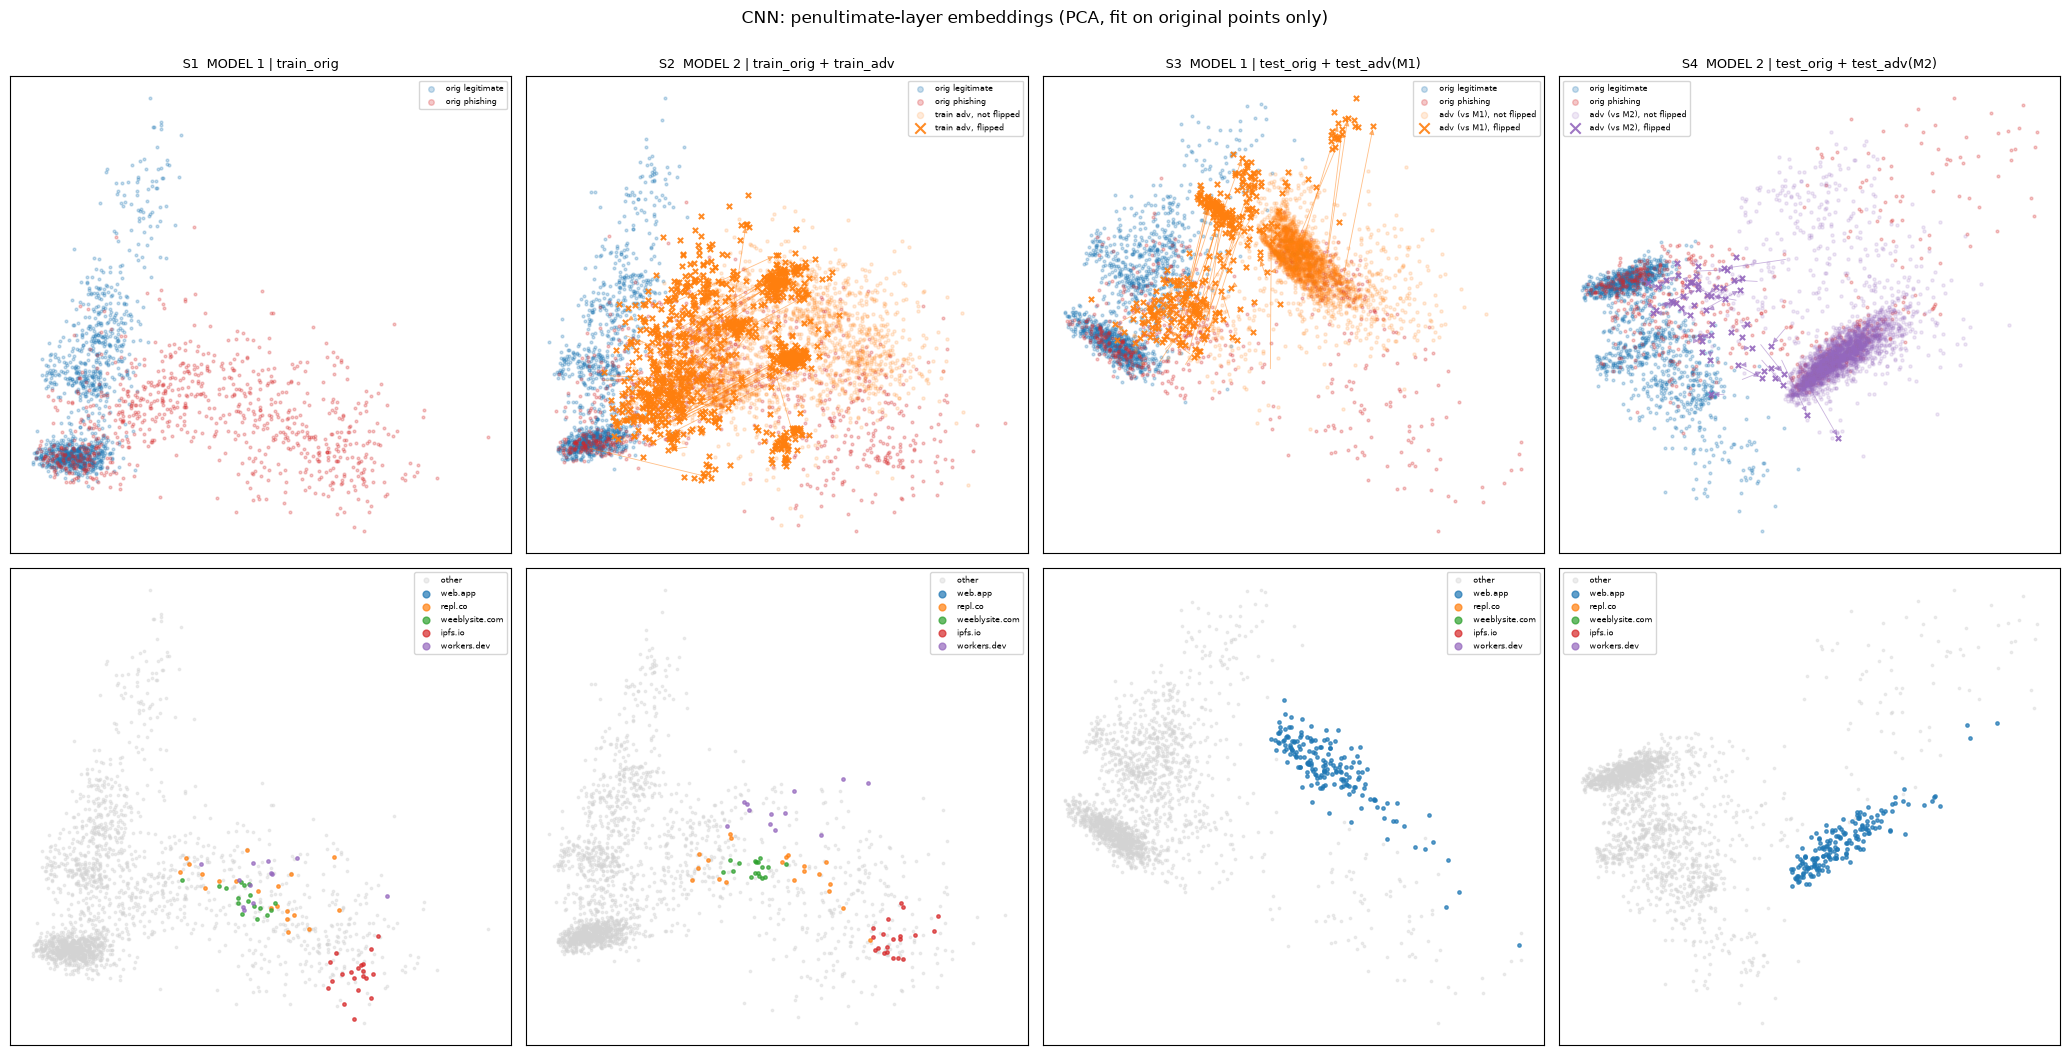

PC1+PC2 variance: 0.813
PC1+PC2 variance: 0.832
PC1+PC2 variance: 0.726
PC1+PC2 variance: 0.776


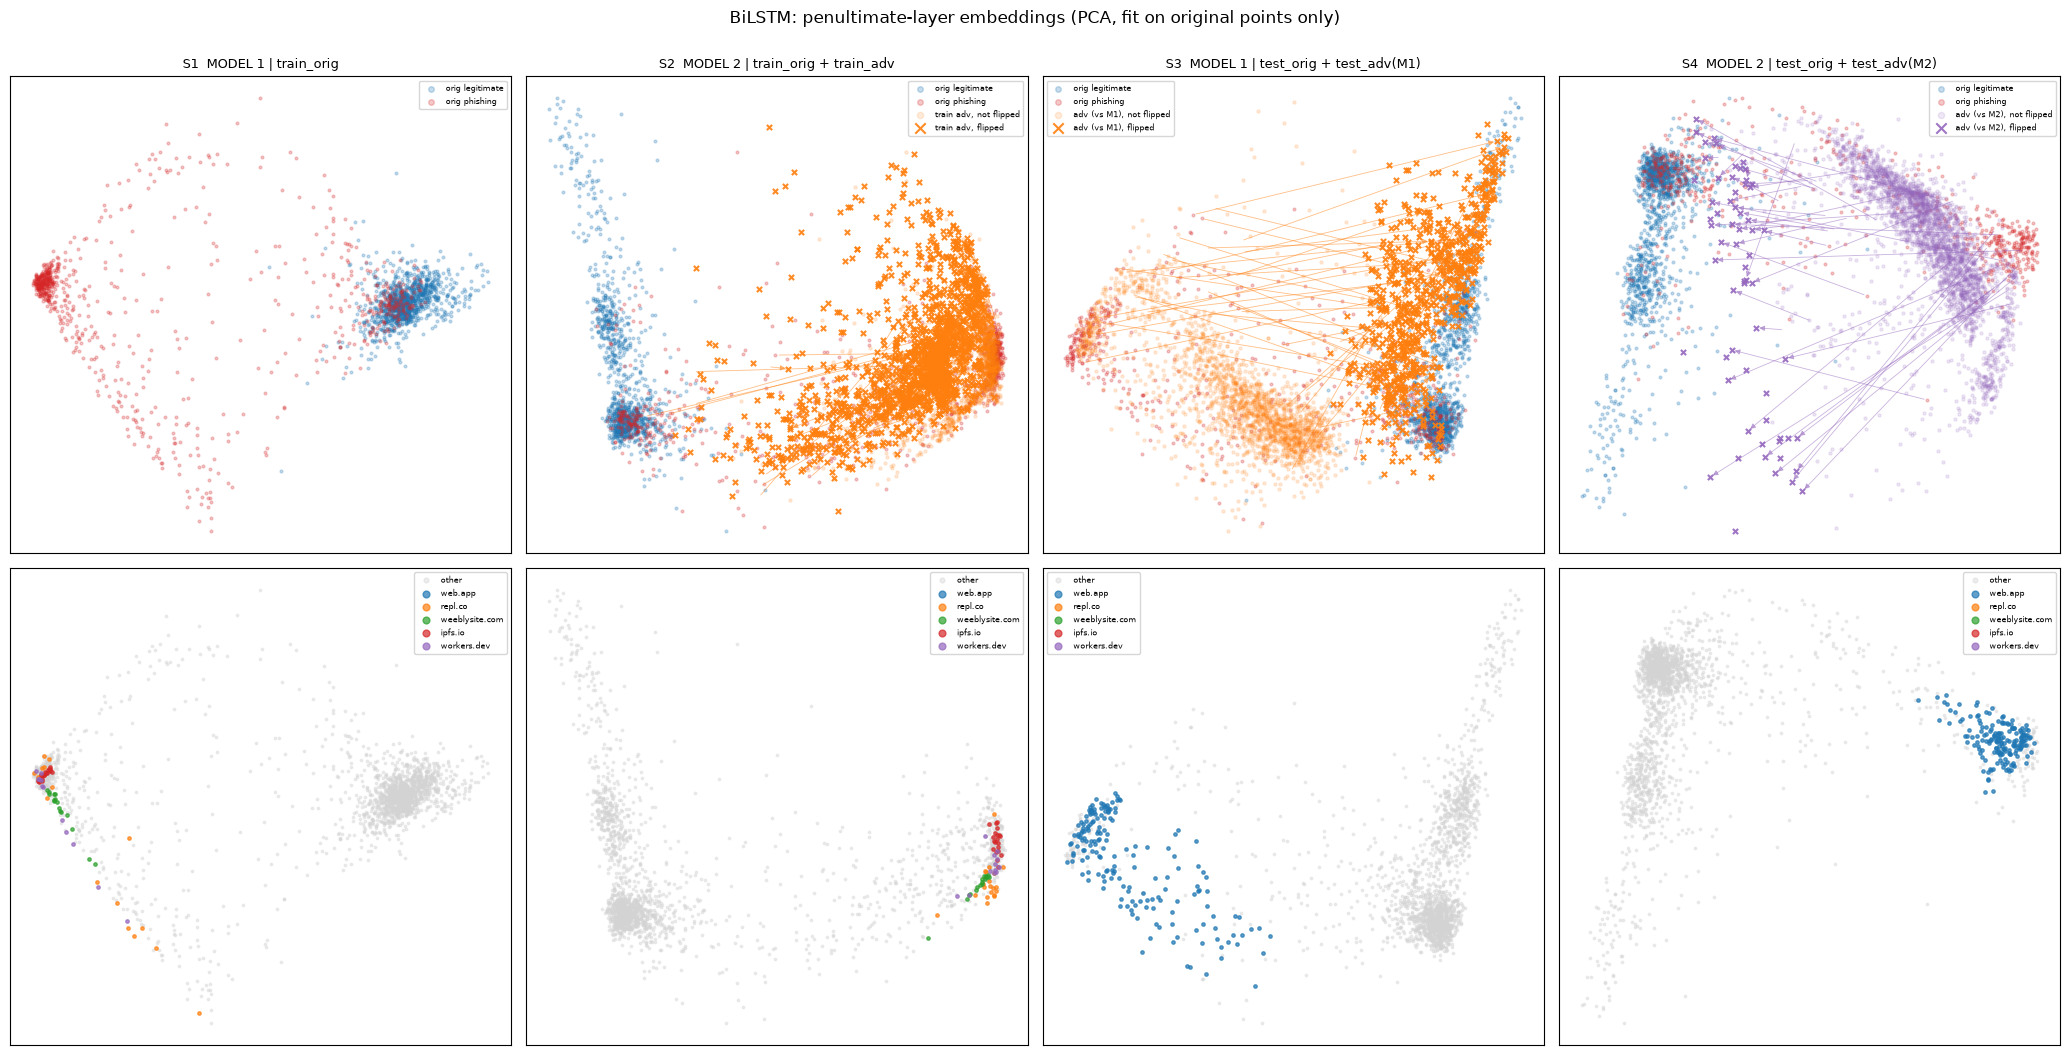

PC1+PC2 variance: 0.952
PC1+PC2 variance: 0.936
PC1+PC2 variance: 0.946
PC1+PC2 variance: 0.926


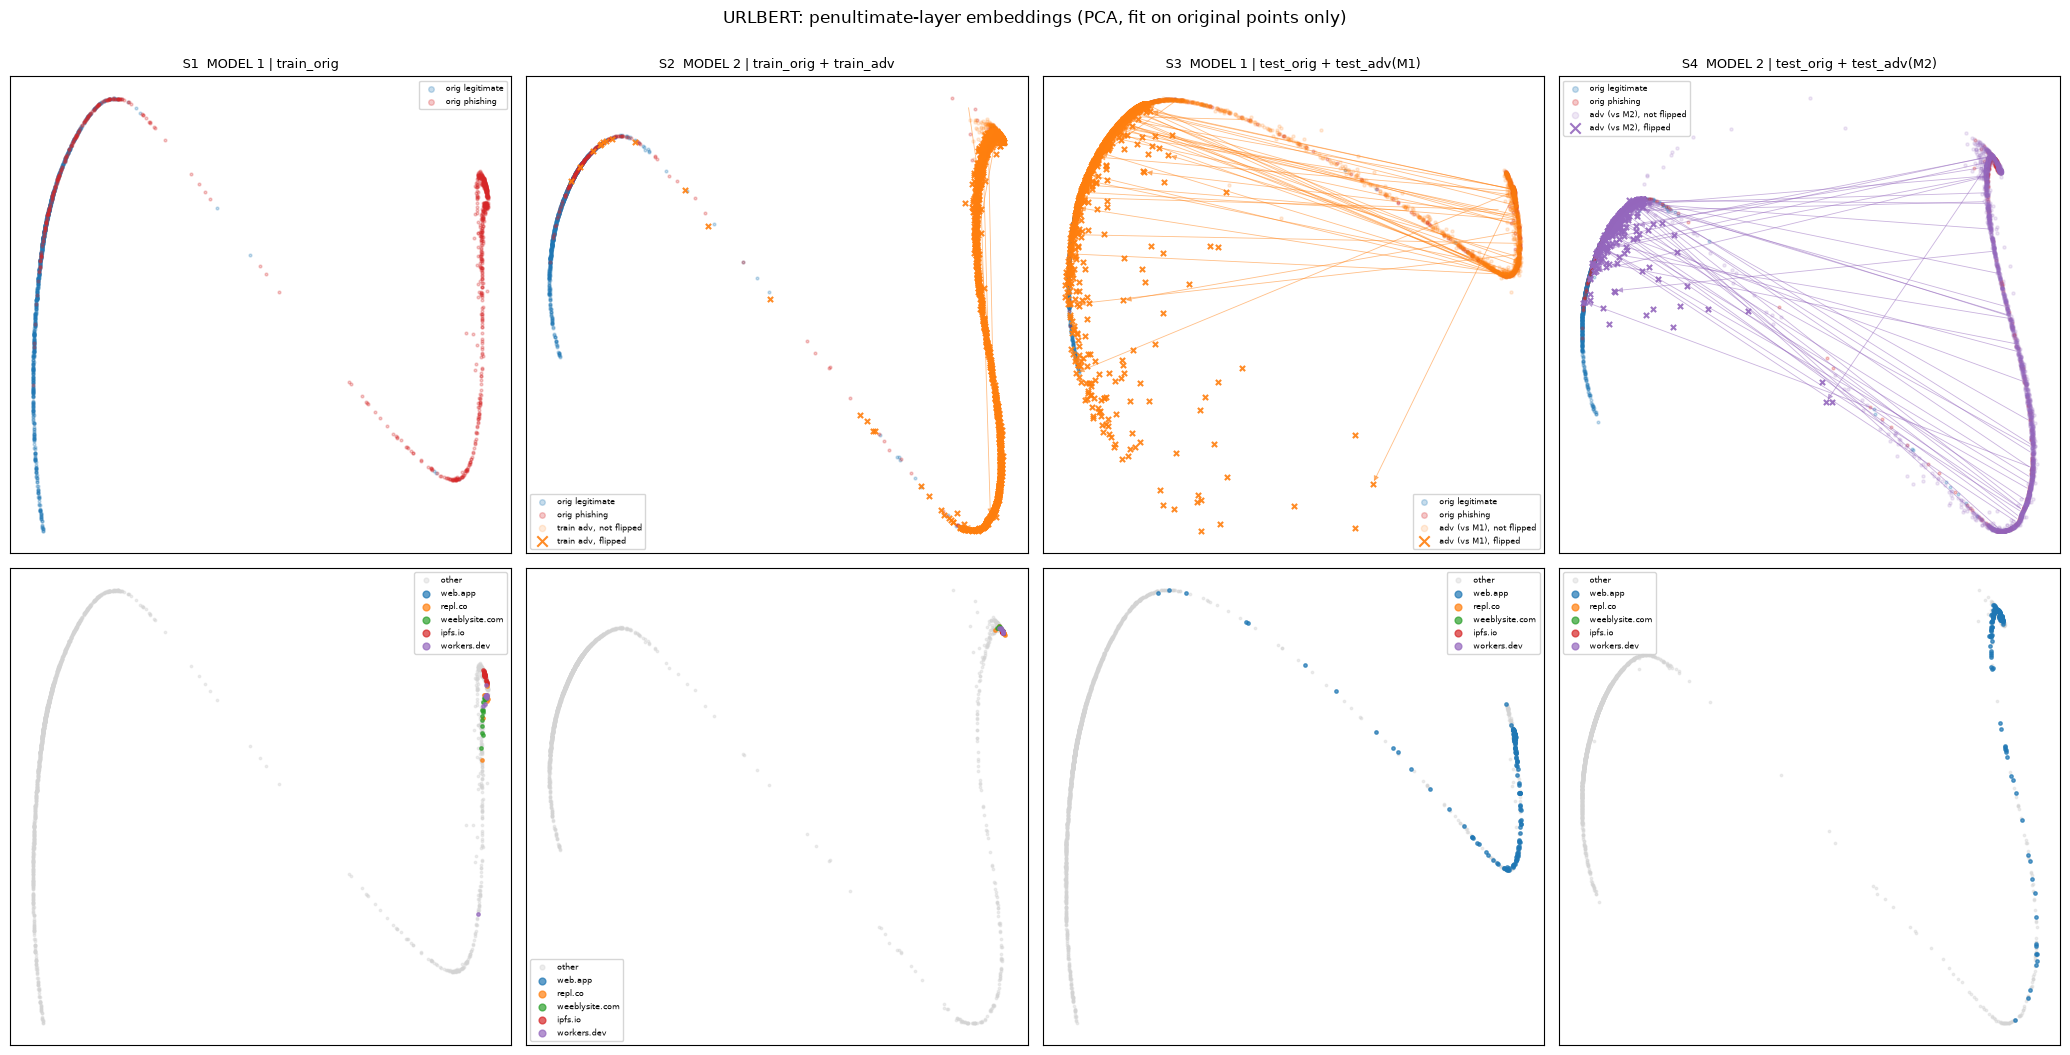

,arch,scenario,adv_set,status,n,knn_legit_frac_orig,knn_legit_frac_adv,median_shift_over_class_gap
0,CNN,S2 MODEL 2,train_adv,flipped,884,0.325339,0.272775,0.870016
1,CNN,S2 MODEL 2,train_adv,not flipped,2116,0.037083,0.036957,0.729517
0,CNN,S3 MODEL 1,test_adv1,flipped,333,0.244244,0.816817,1.130520
1,CNN,S3 MODEL 1,test_adv1,not flipped,2667,0.010149,0.062167,0.948062
0,CNN,S4 MODEL 2,test_adv2,flipped,54,0.695062,0.774074,0.721418
1,CNN,S4 MODEL 2,test_adv2,not flipped,2946,0.008939,0.016384,0.993734
0,BiLSTM,S2 MODEL 2,train_adv,flipped,1500,0.064267,0.014889,0.476649
1,BiLSTM,S2 MODEL 2,train_adv,not flipped,1500,0.001422,0.002578,0.236228
0,BiLSTM,S3 MODEL 1,test_adv1,flipped,739,0.099143,0.808660,1.461254
1,BiLSTM,S3 MODEL 1,test_adv1,not flipped,2261,0.001179,0.054961,0.917340


In [5]:
N_ADV = 3000        # use more adv points here for more stable metrics

metrics = []
for arch in ARCHS:
    fig, axes = plt.subplots(2, len(SCENARIOS), figsize=(5.2 * len(SCENARIOS), 10.5))
    for j, (title, sc) in enumerate(SCENARIOS.items()):
        res = run_scenario(arch, sc)
        if res is None:
            for i in range(2): axes[i, j].text(.5, .5, "model not available", ha="center"); axes[i, j].axis("off")
            axes[0, j].set_title(title, fontsize=9); continue
        draw(axes[0, j], res, "class"); draw(axes[1, j], res, "group")
        axes[0, j].set_title(title, fontsize=9)
        axes[0, j].legend(fontsize=6, markerscale=2, loc="best"); axes[1, j].legend(fontsize=6, markerscale=2, loc="best")
        m = shift_metrics(res)
        if len(m): m.insert(0, "scenario", title.split("|")[0].strip()); m.insert(0, "arch", arch); metrics.append(m)
    fig.suptitle(f"{arch}: penultimate-layer embeddings ({PROJECTION.upper()}, fit on original points only)", y=1.0)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/{arch}_embeddings.png", dpi=160, bbox_inches="tight"); plt.show()

metrics_df = pd.concat(metrics) if metrics else pd.DataFrame()
metrics_df.to_csv(f"{OUT_DIR}/shift_metrics.csv", index=False)
metrics_df

# Tensorflow

In [31]:
def export_projector(arch, scenario_title, outdir=f"{OUT_DIR}/projector"):
    sc = SCENARIOS[scenario_title]; res = run_scenario(arch, sc)
    E = [res["ref_emb"]]; meta = [pd.DataFrame(dict(kind="orig", label=res["ref"]["label"].map(LABEL_NAMES), group=res["ref"]["group"], url=res["ref"]["url"]))]
    for name, a in res["advs"].items():
        E.append(a["emb"]); meta.append(pd.DataFrame(dict(
            kind=a["df"]["flipped"].map({True: f"{name} flipped", False: f"{name} not flipped"}),
            label="phishing(adv)", group=a["df"]["group"], url=a["df"]["url"])))
    os.makedirs(outdir, exist_ok=True)
    tag = f"{arch}_{scenario_title.split()[0]}"
    np.savetxt(f"{outdir}/{tag}_vecs.tsv", np.vstack(E), delimiter="\t")
    pd.concat(meta).to_csv(f"{outdir}/{tag}_meta.tsv", sep="\t", index=False)
    print("wrote", tag)

In [32]:
done, skipped = [], []
for arch in ARCHS:
    for title, sc in SCENARIOS.items():
        if ENCODERS[arch][sc["model"]] is None:
            skipped.append((arch, title.split()[0])); continue
        export_projector(arch, title)
        done.append(f"{arch}_{title.split()[0]}")

print(f"\nwrote {len(done)} scenarios; skipped: {skipped or 'none'}")

PC1+PC2 variance: 0.63
wrote CNN_S1
PC1+PC2 variance: 0.609
wrote CNN_S2
PC1+PC2 variance: 0.536
wrote CNN_S3
PC1+PC2 variance: 0.532
wrote CNN_S4
PC1+PC2 variance: 0.813
wrote BiLSTM_S1
PC1+PC2 variance: 0.832
wrote BiLSTM_S2
PC1+PC2 variance: 0.726
wrote BiLSTM_S3
PC1+PC2 variance: 0.776
wrote BiLSTM_S4
PC1+PC2 variance: 0.952
wrote URLBERT_S1
PC1+PC2 variance: 0.936
wrote URLBERT_S2
PC1+PC2 variance: 0.946
wrote URLBERT_S3
PC1+PC2 variance: 0.926
wrote URLBERT_S4

wrote 12 scenarios; skipped: none
